In [1]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_excel("Sample_Superstore_Cleaned.xlsx")
df["Order Date"] = pd.to_datetime(df["Order Date"])

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10194, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [3]:
print("Total records:", len(df))
print("Missing Order Dates:", df["Order Date"].isna().sum())
print("Missing Sales values:", df["Sales"].isna().sum())
print("Missing Profit values:", df["Profit"].isna().sum())
print("Date range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())

Total records: 10194
Missing Order Dates: 0
Missing Sales values: 0
Missing Profit values: 0
Date range: 2023-01-03 to 2026-12-30


In [4]:
df["Month"] = df["Order Date"].dt.to_period("M")

monthly = df.groupby("Month").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum")
).reset_index()

monthly["Revenue MoM Growth (%)"] = monthly["Revenue"].pct_change() * 100
monthly["Profit MoM Growth (%)"] = monthly["Profit"].pct_change() * 100

monthly["Month"] = monthly["Month"].astype(str)
monthly = monthly.round(2)

monthly

,Month,Revenue,Profit,Revenue MoM Growth (%),Profit MoM Growth (%)
0,2023-01,14518.06,2539.39,NaN,NaN
1,2023-02,4519.89,862.31,-68.87,-66.04
2,2023-03,56933.91,693.45,1159.63,-19.58
3,2023-04,28295.34,3488.84,-50.30,403.11
4,2023-05,26319.77,3196.39,-6.98,-8.38
5,2023-06,34669.48,4999.76,31.72,56.42
6,2023-07,33946.39,-841.48,-2.09,-116.83
7,2023-08,28918.34,5765.22,-14.81,-785.13
8,2023-09,82670.43,8593.63,185.88,49.06
9,2023-10,32413.34,3469.17,-60.79,-59.63


In [5]:
print("Total Revenue:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Overall Profit Margin (%):", round(df["Profit"].sum() / df["Sales"].sum() * 100, 2))
print("Number of months:", monthly.shape[0])

Total Revenue: 2326534.35
Total Profit: 292296.81
Overall Profit Margin (%): 12.56
Number of months: 48


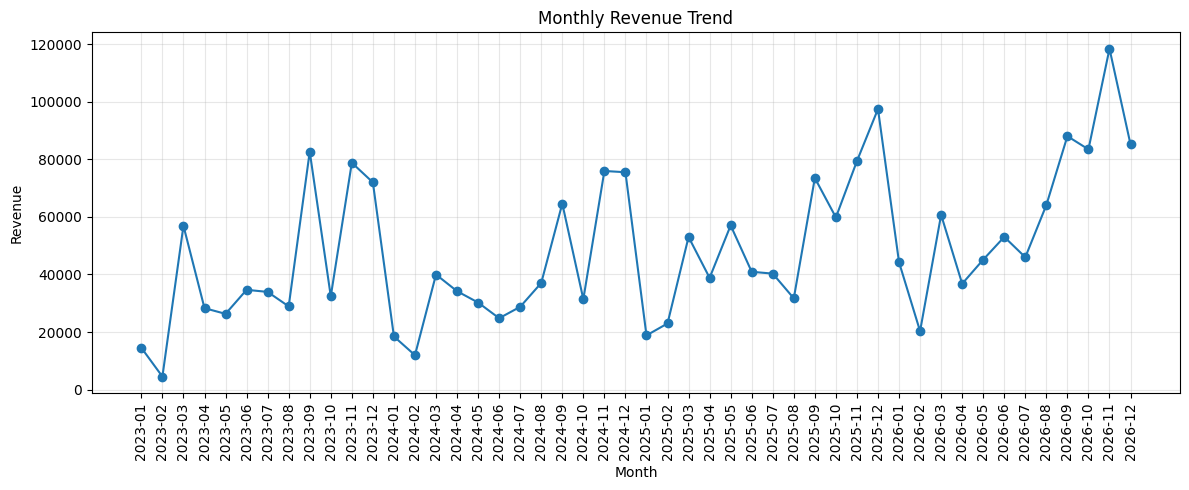

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(monthly["Month"], monthly["Revenue"], marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

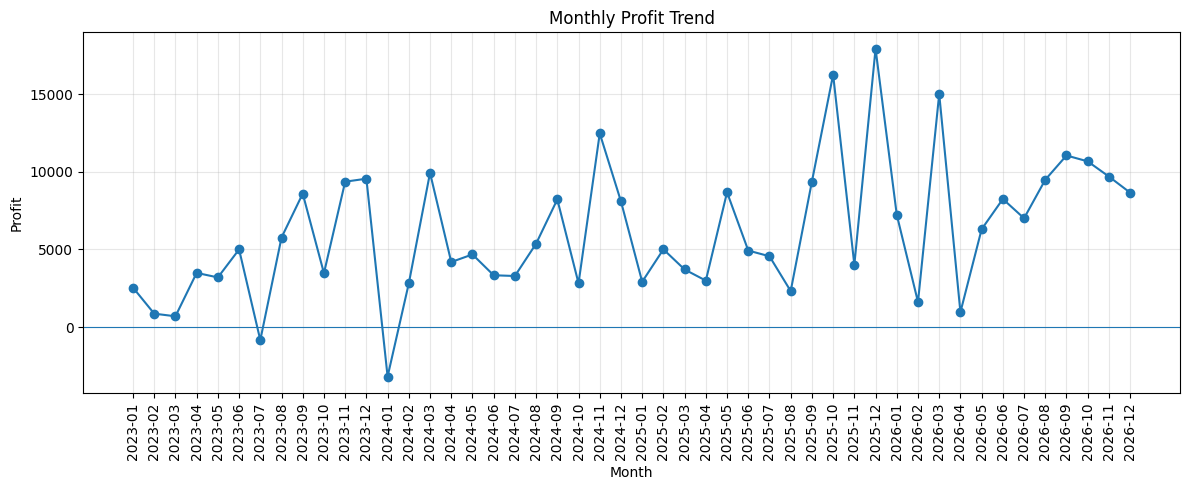

In [7]:
plt.figure(figsize=(12, 5))
plt.plot(monthly["Month"], monthly["Profit"], marker="o")
plt.axhline(0, linewidth=0.8)
plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

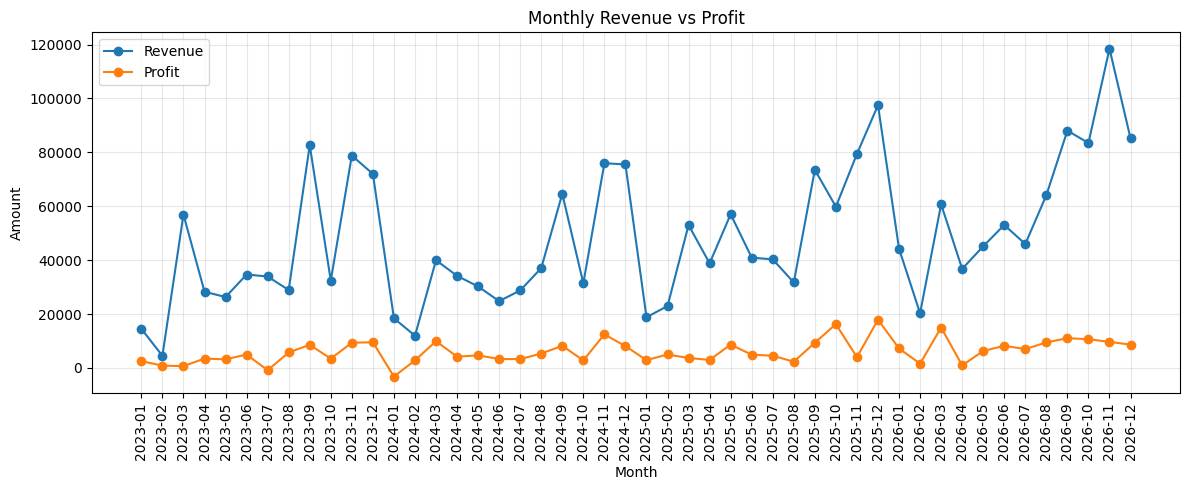

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(monthly["Month"], monthly["Revenue"], marker="o", label="Revenue")
plt.plot(monthly["Month"], monthly["Profit"], marker="o", label="Profit")
plt.title("Monthly Revenue vs Profit")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=90)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
highest_revenue = monthly.loc[monthly["Revenue"].idxmax()]
highest_profit = monthly.loc[monthly["Profit"].idxmax()]
lowest_revenue = monthly.loc[monthly["Revenue"].idxmin()]
lowest_profit = monthly.loc[monthly["Profit"].idxmin()]

print("Highest revenue month:", highest_revenue["Month"], "-", highest_revenue["Revenue"])
print("Highest profit month:", highest_profit["Month"], "-", highest_profit["Profit"])
print("Lowest revenue month:", lowest_revenue["Month"], "-", lowest_revenue["Revenue"])
print("Lowest profit month:", lowest_profit["Month"], "-", lowest_profit["Profit"])

Highest revenue month: 2026-11 - 118454.5
Highest profit month: 2025-12 - 17926.3
Lowest revenue month: 2023-02 - 4519.89
Lowest profit month: 2024-01 - -3189.8
